# Session 1 · Getting to know the steel images

I started with the images. A scratch can be a bright streak on one crop and a thin line on another. Before fitting a model, I wanted to see how much the examples within each class varied. I used the image-only NEU-CLS dataset, where each crop has one defect label. [NEU Surface Defect Database](https://faculty.neu.edu.cn/songkc/en/zdylm/263265/)

In [1]:
from pathlib import Path
import hashlib
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import torch
from IPython.display import display

data_dir = Path("Dataset/NEU-CLS")
artifacts = Path("Artifacts")
artifacts.mkdir(exist_ok=True)
labels = {
    "Cr": "crazing", "In": "inclusion", "Pa": "patches",
    "PS": "pitted_surface", "RS": "rolled_in_scale", "Sc": "scratches",
}
seed = 42

## What was in the download

I read the labels from the filenames and checked the decoded pixels. All 1,800 images were 200 × 200 and grayscale. Two patches, `Pa_101.bmp` and `Pa_105.bmp`, had different names but exactly the same pixels.

In [2]:
files = sorted(data_dir.glob("*.bmp"))
if len(files) != 1800:
    raise ValueError(f"Expected 1,800 BMP files under {data_dir}, found {len(files)}. See README.md.")

records = []
for path in files:
    prefix, number = path.stem.split("_")
    with Image.open(path) as image:
        if image.mode != "L" or image.size != (200, 200):
            raise ValueError(f"Unexpected image format in {path}")
        digest = hashlib.sha256(image.tobytes()).hexdigest()
    records.append((path.as_posix(), labels[prefix], int(number), digest))

images = pd.DataFrame(records, columns=["path", "label", "sample_number", "pixel_sha256"])
counts = images["label"].value_counts().sort_index()
assert len(counts) == 6 and counts.eq(300).all()
assert images.groupby("pixel_sha256")["label"].nunique().max() == 1
print(f"{len(images):,} grayscale images | {images.pixel_sha256.nunique():,} unique pixel arrays")
display(counts.rename("images").to_frame())
display(images.loc[images.pixel_sha256.duplicated(keep=False), ["path", "label"]])

1,800 grayscale images | 1,799 unique pixel arrays


,images
label,
crazing,300
inclusion,300
patches,300
pitted_surface,300
rolled_in_scale,300
scratches,300


,path,label
603,Dataset/NEU-CLS/Pa_101.bmp,patches
607,Dataset/NEU-CLS/Pa_105.bmp,patches


## One split for the whole project

I set aside 45 images per class for validation and another 45 for the final test. That left 210 per class for training. I grouped identical pixel hashes before splitting, so the duplicate patches stayed together. The manifest below is the one I used in every session.

In [3]:
rng = random.Random(seed)
assignments = {}
for label, class_rows in images.groupby("label", sort=True):
    remaining = {"train": 210, "validation": 45, "test": 45}
    groups = list(class_rows.groupby("pixel_sha256", sort=True).size().items())
    # Place larger groups first so an identical pair can fit in one split.
    for digest, size in sorted(groups, key=lambda item: -item[1]):
        eligible = [split for split, space in remaining.items() if space >= size]
        weights = [remaining[split] for split in eligible]
        split = rng.choices(eligible, weights=weights, k=1)[0]
        assignments[digest] = split
        remaining[split] -= size
    assert sum(remaining.values()) == 0

images["split"] = images.pixel_sha256.map(assignments)
split_counts = pd.crosstab(images.label, images.split)[["train", "validation", "test"]]
assert (split_counts.to_numpy() == [210, 45, 45]).all()
assert images.groupby("pixel_sha256").split.nunique().max() == 1

manifest = artifacts / "split_manifest.csv"
columns = ["path", "label", "pixel_sha256", "split"]
# Refuse to silently change a split that a later experiment may already use.
if manifest.exists():
    pd.testing.assert_frame_equal(pd.read_csv(manifest), images[columns])
else:
    temporary = manifest.with_suffix(".tmp")
    images[columns].to_csv(temporary, index=False)
    temporary.replace(manifest)
display(split_counts)
print(f"Saved split: {manifest}")

split,train,validation,test
label,,,
crazing,210,45,45
inclusion,210,45,45
patches,210,45,45
pitted_surface,210,45,45
rolled_in_scale,210,45,45
scratches,210,45,45


Saved split: Artifacts\split_manifest.csv


## What the six defects look like

Each column shows three training images from one class on the same brightness scale. In the scratches column, `Sc_140` has a broad, bright vertical mark. The mark in `Sc_21` is much thinner and branches near the bottom. Both carry the same label.

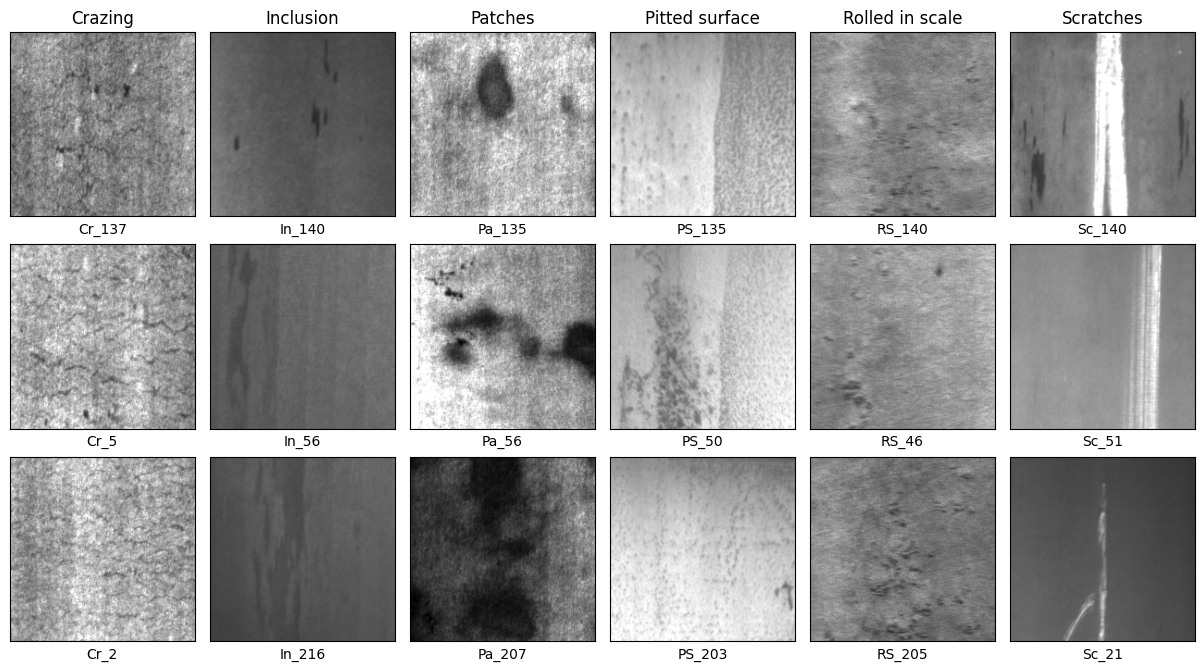

In [4]:
training = images.loc[images.split == "train"].drop_duplicates("pixel_sha256")
fig, axes = plt.subplots(3, 6, figsize=(12, 6.6), layout="constrained")
for column, label in enumerate(labels.values()):
    candidates = training.loc[training.label == label]
    examples = candidates.sample(3, random_state=seed)
    for row, path in enumerate(examples.path):
        ax = axes[row, column]
        with Image.open(path) as image:
            ax.imshow(np.array(image), cmap="gray", vmin=0, vmax=255)
        if row == 0:
            ax.set_title(label.replace("_", " ").capitalize())
        ax.set_xlabel(Path(path).stem)
        ax.set_xticks([])
        ax.set_yticks([])
fig.savefig(artifacts / "training_gallery.png", dpi=130, bbox_inches="tight")
plt.show()

## One scratch, from pixels to a tensor

I used the same scratch for the pixel window and the histogram. The window keeps neighboring values next to one another. The histogram tells me how many pixels have each brightness, but shuffling them would leave the histogram unchanged. The arrangement is part of what makes the streak recognizable.

Sc_140.bmp | shape (200, 200) | type uint8
Center 5 × 5 pixel window:
[[255 255 255 255 255]
 [255 255 255 255 255]
 [255 255 255 255 255]
 [255 255 255 255 255]
 [255 255 255 255 255]]


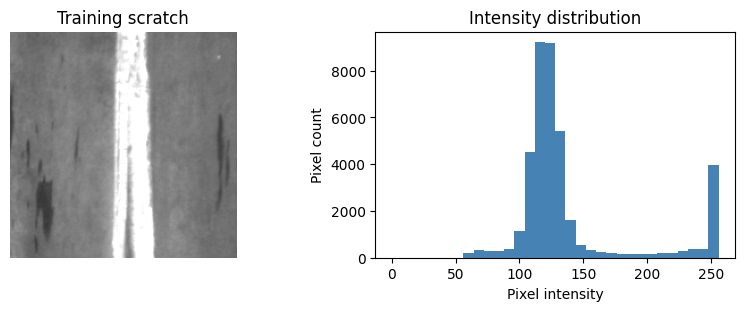

In [5]:
scratch = training.loc[training.label == "scratches"].sample(1, random_state=seed).iloc[0]
with Image.open(scratch.path) as image:
    pixels = np.array(image)
print(f"{Path(scratch.path).name} | shape {pixels.shape} | type {pixels.dtype}")
print("Center 5 × 5 pixel window:")
print(pixels[98:103, 98:103])
fig, (ax_image, ax_hist) = plt.subplots(1, 2, figsize=(8, 3), layout="constrained")
ax_image.imshow(pixels, cmap="gray", vmin=0, vmax=255)
ax_image.set_title("Training scratch")
ax_image.axis("off")
ax_hist.hist(pixels.ravel(), bins=32, range=(0, 256), color="steelblue")
ax_hist.set(xlabel="Pixel intensity", ylabel="Pixel count", title="Intensity distribution")
plt.show()

In [6]:
# Scale intensity to [0, 1] and give the grayscale channel its own axis.
tensor = torch.from_numpy(pixels).float().div(255)
single_image = tensor.unsqueeze(0)
batch = single_image.unsqueeze(0)
print("Height × width:", tuple(tensor.shape))
print("Channel × height × width:", tuple(single_image.shape))
print("Batch × channel × height × width:", tuple(batch.shape))
print(f"Scaled range in this image: {batch.min().item():.3f} to {batch.max().item():.3f}")
print("Flattened ANN input:", tuple(batch.flatten(start_dim=1).shape))
assert batch.shape == (1, 1, 200, 200)
assert torch.equal((batch[0, 0] * 255).round().byte(), torch.from_numpy(pixels))

Height × width: (200, 200)
Channel × height × width: (1, 200, 200)
Batch × channel × height × width: (1, 1, 200, 200)
Scaled range in this image: 0.216 to 1.000
Flattened ANN input: (1, 40000)


## My starting hypothesis

Crazing and rolled-in scale both have irregular dark texture in the gallery, so that was the pair I expected to get mixed up. I kept that prediction to check against the final confusion matrix.

For the next session I flattened each crop into 40,000 values. The pixel directly below the top-left pixel lands at index 200. Its value survives flattening, but the dense layer has to learn how those two positions relate.